#  Student Name: Benjamin David
#  Course Code: CSCI 460 -- Fall 2026
#  Assignment Due Date: 10/25/2026
#  GitHub Link:

# ***Task 1***

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
path = '/content/bank-full.csv'
df = pd.read_csv(path, sep=";")

In [ ]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [ ]:
jobmap = {"admin":0, "unknown":1, "unemployed":2, "management":3, "housemaid":4, "entrepreneur":5, "student":6, "blue-collar":7, "self-employed":8,
"retired":9, "technician":10, "services":11}
df['job'] = df['job'].map(jobmap)

In [ ]:
maritalmap = {"married":0, "divorced":1, "single":2}
df['marital'] = df['marital'].map(maritalmap)

In [ ]:
educationmap = {"unknown":0, "secondary": 1, "primary":2, "tertiary":3}
df['education'] = df['education'].map(educationmap)

In [ ]:
defaultmap = {"yes":1, "no":0}
df['default'] = df['default'].map(defaultmap)

In [ ]:
housingmap = {"yes":1, "no":0}
df['housing'] = df['housing'].map(housingmap)

In [ ]:
loanmap = {"yes":1, "no":0}
df['loan'] = df['loan'].map(loanmap)

In [ ]:
contactmap = {"unknown":0, "telephone":1, "cellular":2}
df['contact'] = df['contact'].map(contactmap)

In [ ]:
df['month'].unique()

array(['may', 'jun', 'jul', 'aug', 'oct', 'nov', 'dec', 'jan', 'feb',
       'mar', 'apr', 'sep'], dtype=object)

In [ ]:
monthmap = {"jan":0, "feb":1, "mar":2, "apr":3, "may":4, "jun":5, "jul":6, "aug":7, "sep":8, "oct":9, "nov":10, "dec":11}
df['month'] = df['month'].map(monthmap)

In [ ]:
poutcomemap = {"unknown":0, "other":1, "failure":2, "success":3}
df['poutcome'] = df['poutcome'].map(poutcomemap)

In [ ]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,3.0,0,3,0,2143,1,0,0,5,4,261,1,-1,0,0,no
1,44,10.0,2,1,0,29,1,0,0,5,4,151,1,-1,0,0,no
2,33,5.0,0,1,0,2,1,1,0,5,4,76,1,-1,0,0,no
3,47,7.0,0,0,0,1506,1,0,0,5,4,92,1,-1,0,0,no
4,33,1.0,2,0,0,1,0,0,0,5,4,198,1,-1,0,0,no


In [ ]:
df = df.dropna()

In [ ]:
X = df.drop(columns=['y'])
y = df['y']

# ***Task 2***

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    stratify=y,
    random_state=42
)

model = GaussianNB()

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

In [ ]:
from sklearn import metrics

In [ ]:
from sklearn.metrics import (
accuracy_score,
confusion_matrix,
ConfusionMatrixDisplay,
f1_score,
classification_report,
)

In [ ]:
# measure the performance
accuracy = accuracy_score(y_pred, y_test)
f1 = f1_score(y_pred, y_test, average="weighted")
print("The accuracy of my Naive Bayes Model is:", accuracy)
print("The F1 Score of my Naive Bayes Model is:", f1)

The accuracy of my Naive Bayes Model is: 0.8334165834165834
The F1 Score of my Naive Bayes Model is: 0.820005533970221


In [ ]:
accuracies = []
f1_scores = []

for i in range(10):

    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=0.30,
        stratify=y,
        random_state=i
    )

    model = GaussianNB()
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, pos_label="yes")

    accuracies.append(accuracy)
    f1_scores.append(f1)

results = pd.DataFrame({
    "Trial": range(1, 11),
    "Accuracy": accuracies,
    "F1-score": f1_scores
})

results.loc["Mean"] = ["", results["Accuracy"].mean(), results["F1-score"].mean()]
results.loc["Std Dev"] = ["", results["Accuracy"].std(), results["F1-score"].std()]

print(results.round(4))

        Trial  Accuracy  F1-score
0           1    0.8280    0.4200
1           2    0.8228    0.3988
2           3    0.8268    0.4150
3           4    0.8218    0.4094
4           5    0.8303    0.4248
5           6    0.8294    0.4110
6           7    0.8223    0.4062
7           8    0.8312    0.4332
8           9    0.8259    0.4177
9          10    0.8334    0.4225
Mean             0.8272    0.4159
Std Dev          0.0038    0.0095


In [ ]:
print(confusion_matrix(y_test, y_pred, labels=["no", "yes"]))


[[9279 1336]
 [ 665  732]]


# ***Task 3***

   Training %  Mean Accuracy  SD Accuracy  Mean F1   SD F1
0          10         0.8297       0.0073   0.4127  0.0093
1          20         0.8279       0.0047   0.4116  0.0086
2          30         0.8269       0.0037   0.4078  0.0066
3          40         0.8267       0.0032   0.4082  0.0062
4          50         0.8272       0.0024   0.4112  0.0063
5          60         0.8273       0.0037   0.4136  0.0086
6          70         0.8272       0.0040   0.4159  0.0100
7          80         0.8274       0.0050   0.4195  0.0108
8          90         0.8267       0.0058   0.4201  0.0168


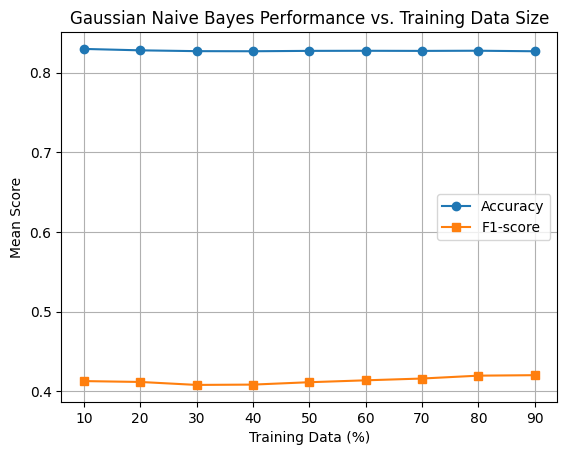

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

results = []

for train_percent in range(10, 100, 10):

    accuracies = []
    f1_scores = []

    for i in range(10):

        X_train, X_test, y_train, y_test = train_test_split(
            X, y,
            train_size=train_percent / 100,
            stratify=y,
            random_state=i
        )

        model = GaussianNB()
        model.fit(X_train, y_train)

        y_pred = model.predict(X_test)

        accuracy = accuracy_score(y_test, y_pred)
        f1 = f1_score(y_test, y_pred, pos_label="yes")

        accuracies.append(accuracy)
        f1_scores.append(f1)

    results.append({
        "Training %": train_percent,
        "Mean Accuracy": pd.Series(accuracies).mean(),
        "SD Accuracy": pd.Series(accuracies).std(),
        "Mean F1": pd.Series(f1_scores).mean(),
        "SD F1": pd.Series(f1_scores).std()
    })

results_df = pd.DataFrame(results)

print(results_df.round(4))

plt.plot(results_df["Training %"], results_df["Mean Accuracy"],
         marker="o", label="Accuracy")

plt.plot(results_df["Training %"], results_df["Mean F1"],
         marker="s", label="F1-score")

plt.xlabel("Training Data (%)")
plt.ylabel("Mean Score")
plt.title("Gaussian Naive Bayes Performance vs. Training Data Size")
plt.xticks(range(10, 100, 10))
plt.legend()
plt.grid(True)
plt.show()

# **Final Report**

  For this programming assignment, a UCI Machine Learning Repository Dataset was used, containing bank client data for the purpose of classifying and predicting if customers will subscribe to a term deposit. Some challenges faced in the data cleaning and preprocessing where mapping categorical values and dealing with null values. Categorical values need to be converted into numbers for these models to understand, so to preprocess the data each unique categorical value was mapped to an integer starting from index 0. Using the pandas libraries, null values were easily removed as well using the dropna() command.

  After preparing the data we created a Gaussian Naive Bayes Model, splitting the data into 70% training and 30% testing. The data was split using stratified random sampling so that the target variable was proportionally represented in our training set. The experiment was then repeated 10 times using a random state of "i" (an integer between 0 and 9) for reproducibility of our results. The accuracy and F1-Scores were gathered for each trial, as well as the mean and standard deviation of those metrics.

  The next step was to test different training percentages from 10% to 90%, increasing by 10% each time. Each of these train-test splits were also repeated ten times, and again the mean accuracies and standard deviations of each percentage were gathered. To visualize the results we plotted the different accuracy scores and F1-scores by their percentage.

  From the results of the first step using only the 70% training and 30% testing split, the model had a mean accuracy of 82.72% and a mean F1-score of 0.4159. The standard deviations were relatively low, at 0.0038 for accuracy and 0.0095 for F1-score, suggesting that the model performed consistently across the ten trials. Although the accuracy was relatively high, the low F1-score suggests that the model struggled to correctly identify customers who would subscribe. This is likely due to the imbalance in the target feature, where most customers did not subscribe, allowing the model to achieve higher accuracy by favoring the majority class.
  
  In the second experiment, increasing the training percentage did not noticeably improve accuracy, which remained between 82.67% and 82.97%. Interestingly, the highest accuracy occurred with only 10% training data. However, the F1-score generally improved after 30% training, increasing from 0.4078 to 0.4201 at 90% training. This suggests that additional training data may have slightly improved the model's ability to predict positive cases, despite having little effect on overall accuracy.
  
  The standard deviations also showed an interesting pattern. Accuracy had its lowest standard deviation of 0.0024 at 50% training, while the F1-score had its lowest standard deviation of 0.0062 at 40% training. Both increased at higher training percentages, with the F1 standard deviation reaching 0.0168 at 90%. This may be because larger training sets leave fewer observations for testing, making results more sensitive to the particular samples selected.
  
  Overall, increasing training data had little impact on accuracy and only slightly improved the F1-score. The class imbalance and the Gaussian Naive Bayes assumption that features are conditionally independent likely limited the model's performance. Additionally, mapping categorical values to integers may have affected the results because these numbers may not accurately convert the information captured in those variables (each category may not be one integer distance away from each other).